# Runtime profiling

Visualizes the runs written by `run_profiling.py` to `data/` (one JSON file per (env, policy, budget, bins, seed) run),
collected with `collect_runtimes.sh` and `collect_scaling.sh`.

In [1]:
import json
import sys
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(os.path.abspath('')), "..", "..")))
from examples.plot_style import ANNOTATION_GREY, AREA_ALPHA, MARKERS, PALETTE
from IPython.display import Markdown, display
import numpy as np

DATA_DIR = Path("data")
POLICY_ORDER = ["Random", "Q-Learning", "ActiveLearning", "Entropy"]
# fixed color/marker per policy, so a policy looks the same in every plot
POLICY_STYLE = {p: dict(color=c, marker=m) for p, c, m in zip(POLICY_ORDER, PALETTE, MARKERS)}

# timing categories reported by verigym.create_abstraction, with display labels
TIME_CATEGORIES = {
    "time_simulate": "Simulation",
    "time_policy_update": "Policy update",
    "time_model_construction": "Model construction",
}
STORMPY_LABEL = "Stormpy (build + check)"

# load all runs (non-recursive, so data/quick is ignored)

all_records = [json.loads(f.read_text()) for f in sorted(DATA_DIR.glob("*.json"))]
for r in all_records:
    # older runs did not record the model checking time
    r["t_stormpy"] = r["t_stormpy_build"] + r.get("t_model_check", 0.0)
    # everything needed to obtain the policy; the evaluation itself is excluded
    r["time_total"] = sum(r[k] for k in TIME_CATEGORIES) + r["t_stormpy"]
print(f"Loaded {len(all_records)} runs from {DATA_DIR}")


Loaded 344 runs from data


## Runtime breakdown per abstraction size

Results of `collect_runtimes.sh`: a fixed environment, policy and budget with an increasing number of state bins.
Bars show the mean over seeds; the labels below the bars give the number of abstract states and, in brackets, the mean
number of explored states. The right panel shows the same breakdown as a share of the total.

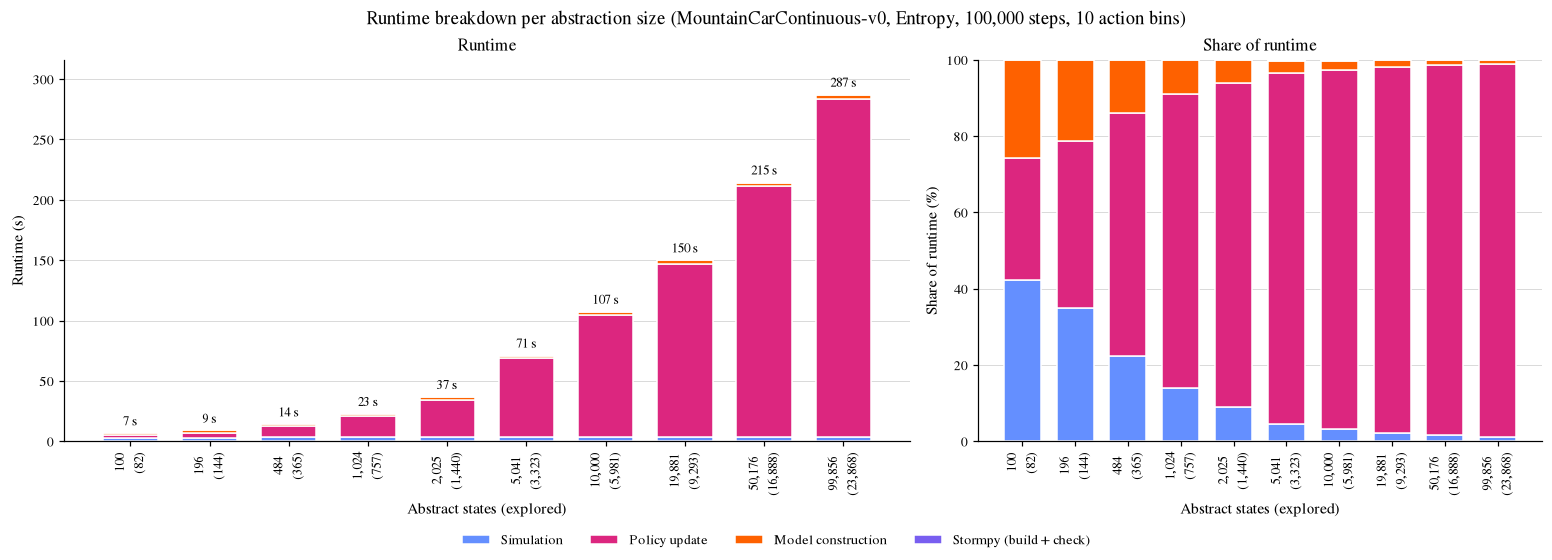

In [2]:
BREAKDOWN_ENV = "MountainCarContinuous-v0"
POLICY = "Entropy"
BUDGET = 100_000
BINS_ACTIONS = 10

# seeds per number of state bins for this env, policy, budget and action bins
breakdown = defaultdict(list)
for r in all_records:
    if (r["env"], r["policy"], r["budget"], r["bins_actions"]) == (BREAKDOWN_ENV, POLICY, BUDGET, BINS_ACTIONS):
        breakdown[r["bins_states"]].append(r)
bins = sorted(breakdown)
if not bins:
    raise ValueError(f"No runs for {BREAKDOWN_ENV}, {POLICY}, budget {BUDGET}, {BINS_ACTIONS} action bins in {DATA_DIR}, "
                     "run collect_runtimes.sh")

categories = {**TIME_CATEGORIES, "t_stormpy": STORMPY_LABEL}
means = {key: np.array([np.mean([r[key] for r in breakdown[b]]) for b in bins]) for key in categories}
totals = sum(means.values())
tick_labels = [f"{breakdown[b][0]['n_abstract_states']:,.0f}\n({np.mean([r['explored_states'] for r in breakdown[b]]):,.0f})"
               for b in bins]

x = np.arange(len(bins))
fig, (ax_abs, ax_rel) = plt.subplots(1, 2, figsize=(14, 5), width_ratios=(3, 2))
bottom_abs, bottom_rel = np.zeros(len(bins)), np.zeros(len(bins))
for (key, label), color in zip(categories.items(), PALETTE):
    ax_abs.bar(x, means[key], bottom=bottom_abs, width=0.7, label=label, color=color, edgecolor="white", linewidth=1)
    ax_rel.bar(x, 100 * means[key] / totals, bottom=bottom_rel, width=0.7, color=color, edgecolor="white", linewidth=1)
    bottom_abs += means[key]
    bottom_rel += 100 * means[key] / totals

# total runtime above each bar
for xi, total in zip(x, totals):
    ax_abs.annotate(f"{total:.0f} s", (xi, total), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize="small")
ax_abs.set_ylim(top=totals.max() * 1.1)  # room for the total labels

for ax in (ax_abs, ax_rel):
    ax.set_xticks(x, tick_labels, rotation=90, fontsize="small")
    ax.set_xlabel("Abstract states (explored)")
    ax.set_axisbelow(True)
ax_abs.set_ylabel("Runtime (s)")
ax_rel.set_ylabel("Share of runtime (%)")
ax_rel.set_ylim(0, 100)
ax_abs.set_title("Runtime")
ax_rel.set_title("Share of runtime")
fig.suptitle(f"Runtime breakdown per abstraction size ({BREAKDOWN_ENV}, {POLICY}, {BUDGET:,} steps, "
             f"{BINS_ACTIONS} action bins)")
fig.legend(*ax_abs.get_legend_handles_labels(), loc="outside lower center", ncol=len(categories), frameon=False)
plt.show()


## Scaling with the exploration budget

Results of `collect_scaling.sh`: one JSON file per (env, policy, budget, seed) run in `data/`, with 10 state bins and 10 action bins.

In [3]:
ENV = "MountainCarContinuous-v0"

BINS = (10, 10)  # (state bins, action bins) used by collect_scaling.sh

records = [r for r in all_records if r["env"] == ENV and (r["bins_states"], r["bins_actions"]) == BINS]

# group the seeds of each (policy, budget): runs[policy][budget] -> list of records
runs = defaultdict(lambda: defaultdict(list))
for r in records:
    runs[r["policy"]][r["budget"]].append(r)
policies = [p for p in POLICY_ORDER if p in runs]

def series(policy, key):
    """Budgets and mean/min/max over seeds of `key`, sorted by budget."""
    budgets = sorted(runs[policy])
    values = [np.array([r[key] for r in runs[policy][b]]) for b in budgets]
    return (np.array(budgets), np.array([v.mean() for v in values]),
            np.array([v.min() for v in values]), np.array([v.max() for v in values]))

print(f"Loaded {len(records)} runs for {ENV}: " + ", ".join(f"{p} ({sum(map(len, runs[p].values()))})" for p in policies))


Loaded 234 runs for MountainCarContinuous-v0: Random (60), Q-Learning (60), ActiveLearning (59), Entropy (55)


### Summary table

Means over seeds; ± is the standard deviation over seeds (only shown with more than one seed).

In [4]:
def fmt(values, digits=1):
    values = np.asarray(values, dtype=float)
    s = f"{values.mean():.{digits}f}"
    return s + f" ± {values.std():.{digits}f}" if len(values) > 1 else s

header = ["Policy", "Budget", "Seeds", "Total time (s)", "Simulation (s)", "Policy update (s)",
          "Model constr. (s)", "Explored S", "Explored SA", "Return original"]
rows = []
for p in policies:
    for b in sorted(runs[p]):
        rs = runs[p][b]
        col = lambda k: [r[k] for r in rs]
        rows.append([p, f"{b:,}", str(len(rs)), fmt(col("time_total"), 2), fmt(col("time_simulate"), 2),
                     fmt(col("time_policy_update"), 2), fmt(col("time_model_construction"), 2),
                     fmt(col("explored_states"), 0), fmt(col("explored_state_action_pairs"), 0),
                     fmt(col("mean_reward_original"))])

lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
lines += ["| " + " | ".join(row) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| Policy | Budget | Seeds | Total time (s) | Simulation (s) | Policy update (s) | Model constr. (s) | Explored S | Explored SA | Return original |
|---|---|---|---|---|---|---|---|---|---|
| Random | 1,000 | 5 | 0.05 ± 0.00 | 0.03 ± 0.00 | 0.00 ± 0.00 | 0.02 ± 0.00 | 19 ± 9 | 157 ± 70 | -1.8 ± 1.2 |
| Random | 2,000 | 5 | 0.09 ± 0.00 | 0.05 ± 0.00 | 0.00 ± 0.00 | 0.04 ± 0.00 | 36 ± 14 | 278 ± 93 | -4.4 ± 3.0 |
| Random | 5,000 | 5 | 0.22 ± 0.00 | 0.12 ± 0.00 | 0.00 ± 0.00 | 0.10 ± 0.00 | 47 ± 7 | 380 ± 51 | -1.7 ± 0.6 |
| Random | 10,000 | 5 | 0.43 ± 0.01 | 0.24 ± 0.00 | 0.00 ± 0.00 | 0.19 ± 0.00 | 51 ± 7 | 433 ± 67 | -1.2 ± 1.0 |
| Random | 20,000 | 5 | 0.84 ± 0.01 | 0.47 ± 0.00 | 0.00 ± 0.00 | 0.37 ± 0.00 | 50 ± 5 | 422 ± 59 | -1.1 ± 1.3 |
| Random | 50,000 | 5 | 2.15 ± 0.08 | 1.21 ± 0.05 | 0.00 ± 0.00 | 0.94 ± 0.03 | 61 ± 5 | 539 ± 24 | -2.2 ± 0.9 |
| Random | 100,000 | 5 | 4.20 ± 0.07 | 2.36 ± 0.04 | 0.00 ± 0.00 | 1.84 ± 0.04 | 62 ± 3 | 559 ± 17 | -1.5 ± 1.0 |
| Random | 200,000 | 5 | 8.40 ± 0.11 | 4.72 ± 0.06 | 0.00 ± 0.00 | 3.68 ± 0.05 | 64 ± 3 | 582 ± 18 | 17.0 ± 37.4 |
| Random | 500,000 | 5 | 21.29 ± 0.26 | 11.97 ± 0.16 | 0.00 ± 0.00 | 9.31 ± 0.10 | 70 ± 2 | 630 ± 22 | 30.5 ± 52.0 |
| Random | 1,000,000 | 5 | 41.52 ± 0.12 | 23.31 ± 0.07 | 0.00 ± 0.00 | 18.21 ± 0.08 | 71 ± 2 | 652 ± 9 | 25.7 ± 55.6 |
| Random | 2,000,000 | 5 | 84.50 ± 1.47 | 47.31 ± 0.75 | 0.00 ± 0.00 | 37.19 ± 0.75 | 72 ± 2 | 670 ± 10 | 74.6 ± 38.0 |
| Random | 5,000,000 | 5 | 208.65 ± 2.55 | 116.84 ± 1.42 | 0.00 ± 0.00 | 91.80 ± 1.18 | 76 ± 2 | 711 ± 9 | 94.2 ± 0.8 |
| Q-Learning | 1,000 | 5 | 0.07 ± 0.00 | 0.05 ± 0.00 | 0.00 ± 0.00 | 0.02 ± 0.00 | 19 ± 5 | 158 ± 37 | 0.0 ± 0.0 |
| Q-Learning | 2,000 | 5 | 0.15 ± 0.00 | 0.10 ± 0.00 | 0.01 ± 0.00 | 0.04 ± 0.00 | 45 ± 10 | 363 ± 79 | 0.0 ± 0.0 |
| Q-Learning | 5,000 | 5 | 0.36 ± 0.00 | 0.24 ± 0.00 | 0.02 ± 0.01 | 0.09 ± 0.00 | 37 ± 11 | 297 ± 85 | 0.0 ± 0.0 |
| Q-Learning | 10,000 | 5 | 0.71 ± 0.01 | 0.46 ± 0.00 | 0.07 ± 0.01 | 0.18 ± 0.00 | 47 ± 10 | 411 ± 87 | 0.0 ± 0.0 |
| Q-Learning | 20,000 | 5 | 1.47 ± 0.03 | 0.91 ± 0.01 | 0.19 ± 0.02 | 0.36 ± 0.00 | 51 ± 4 | 444 ± 39 | 0.0 ± 0.0 |
| Q-Learning | 50,000 | 5 | 3.87 ± 0.09 | 2.32 ± 0.07 | 0.63 ± 0.03 | 0.92 ± 0.03 | 54 ± 2 | 484 ± 29 | 0.0 ± 0.0 |
| Q-Learning | 100,000 | 5 | 7.97 ± 0.13 | 4.60 ± 0.05 | 1.56 ± 0.06 | 1.81 ± 0.02 | 57 ± 2 | 532 ± 11 | 0.0 ± 0.0 |
| Q-Learning | 200,000 | 5 | 16.83 ± 0.15 | 9.20 ± 0.04 | 4.01 ± 0.13 | 3.63 ± 0.04 | 60 ± 4 | 557 ± 19 | 0.0 ± 0.0 |
| Q-Learning | 500,000 | 5 | 47.65 ± 0.31 | 22.96 ± 0.10 | 15.59 ± 0.35 | 9.09 ± 0.04 | 64 ± 4 | 586 ± 27 | 0.0 ± 0.0 |
| Q-Learning | 1,000,000 | 5 | 115.98 ± 1.18 | 46.56 ± 0.57 | 50.84 ± 0.39 | 18.57 ± 0.36 | 68 ± 3 | 602 ± 14 | 0.0 ± 0.0 |
| Q-Learning | 2,000,000 | 5 | 323.84 ± 1.48 | 94.92 ± 0.41 | 191.60 ± 1.34 | 37.32 ± 0.32 | 68 ± 1 | 627 ± 25 | 0.0 ± 0.0 |
| Q-Learning | 5,000,000 | 5 | 1612.27 ± 14.73 | 241.64 ± 4.38 | 1274.80 ± 11.76 | 95.83 ± 1.88 | 73 ± 4 | 656 ± 13 | 3.6 ± 6.3 |
| ActiveLearning | 1,000 | 5 | 0.07 ± 0.00 | 0.05 ± 0.00 | 0.00 ± 0.00 | 0.02 ± 0.00 | 26 ± 12 | 204 ± 80 | 0.0 ± 0.0 |
| ActiveLearning | 2,000 | 5 | 0.14 ± 0.00 | 0.10 ± 0.00 | 0.00 ± 0.00 | 0.04 ± 0.00 | 32 ± 6 | 270 ± 55 | 0.0 ± 0.0 |
| ActiveLearning | 5,000 | 5 | 0.37 ± 0.01 | 0.24 ± 0.01 | 0.03 ± 0.00 | 0.10 ± 0.00 | 57 ± 2 | 525 ± 20 | 0.0 ± 0.0 |
| ActiveLearning | 10,000 | 5 | 0.75 ± 0.01 | 0.47 ± 0.01 | 0.10 ± 0.01 | 0.19 ± 0.00 | 67 ± 1 | 611 ± 21 | -8.4 ± 16.8 |
| ActiveLearning | 20,000 | 5 | 1.55 ± 0.02 | 0.91 ± 0.01 | 0.26 ± 0.01 | 0.37 ± 0.00 | 70 ± 1 | 658 ± 15 | -17.8 ± 14.8 |
| ActiveLearning | 50,000 | 5 | 4.04 ± 0.09 | 2.30 ± 0.05 | 0.81 ± 0.03 | 0.92 ± 0.03 | 72 ± 2 | 678 ± 27 | 26.3 ± 58.7 |
| ActiveLearning | 100,000 | 5 | 8.24 ± 0.14 | 4.56 ± 0.10 | 1.86 ± 0.02 | 1.82 ± 0.03 | 71 ± 1 | 686 ± 8 | -17.5 ± 22.4 |
| ActiveLearning | 200,000 | 5 | 17.29 ± 0.16 | 9.13 ± 0.05 | 4.50 ± 0.09 | 3.65 ± 0.04 | 74 ± 0 | 697 ± 5 | -0.9 ± 46.7 |
| ActiveLearning | 500,000 | 5 | 48.62 ± 0.47 | 23.20 ± 0.26 | 16.19 ± 0.11 | 9.22 ± 0.16 | 73 ± 3 | 696 ± 7 | 19.4 ± 61.4 |
| ActiveLearning | 1,000,000 | 5 | 117.22 ± 1.11 | 47.24 ± 0.41 | 51.34 ± 0.68 | 18.63 ± 0.34 | 75 ± 1 | 707 ± 8 | 75.9 ± 36.1 |
| ActiveLearning | 2,000,000 | 5 | 319.66 ± 1.94 | 95.28 ± 0.86 | 186.86 ± 2.11 | 37.52 ± 0.48 | 72 ± 1 | 701 ± 7 | 74.6 ± 37.3 |
| ActiveLearning | 5,000,000 | 4 | 1572.65 ± 3.51 | 238.71 ± 1.77 | 1239.65 ± 4.07 | 94.28 ± 0.37 | 75 ± 3 | 714 ± 14 | 23.8 ± 41.3 |
| Entropy | 1,000 | 5 | 0.06 ± 0.00 | 0.04 ± 0.00 | 0.00 ± 0.00 | 0.02 ± 0.00 | 23 ± 17 | 178 ± 118 | 0.0 ± 0.0 |
| Entropy | 2,000 | 5 | 0.11 ± 0.00 | 0.07 ± 0.00 | 0.01 ± 0.00 | 0.04 ± 0.00 | 37 ± 12 | 311 ± 97 | 0.0 ± 0.0 |
| Entropy | 5,000 | 5 | 0.30 ± 0.01 | 0.16 ± 0.00 | 0.04 ± 0.01 | 0.10 ± 0.00 | 51 ± 7 | 458 ± 74 | 0.0 ± 0.0 |
| Entropy | 10,000 | 5 | 0.62 ± 0.02 | 0.31 ± 0.01 | 0.11 ± 0.01 | 0.19 ± 0.00 | 68 ± 5 | 641 ± 48 | 8.0 ± 43.2 |
| Entropy | 20,000 | 5 | 1.29 ± 0.02 | 0.61 ± 0.00 | 0.30 ± 0.02 | 0.37 ± 0.00 | 78 ± 2 | 747 ± 29 | 44.0 ± 55.0 |
| Entropy | 50,000 | 5 | 3.44 ± 0.03 | 1.54 ± 0.01 | 0.98 ± 0.03 | 0.92 ± 0.01 | 80 ± 4 | 779 ± 45 | 71.8 ± 40.0 |
| Entropy | 100,000 | 5 | 6.84 ± 1.18 | 2.90 ± 0.52 | 2.19 ± 0.36 | 1.75 ± 0.31 | 82 ± 1 | 813 ± 12 | 62.9 ± 60.7 |
| Entropy | 200,000 | 5 | 15.18 ± 0.12 | 6.17 ± 0.03 | 5.29 ± 0.13 | 3.72 ± 0.03 | 80 ± 1 | 793 ± 11 | -2.1 ± 48.1 |
| Entropy | 500,000 | 5 | 44.27 ± 0.47 | 15.72 ± 0.19 | 19.11 ± 0.27 | 9.44 ± 0.09 | 81 ± 1 | 809 ± 11 | 54.5 ± 45.7 |
| Entropy | 1,000,000 | 5 | 108.72 ± 0.77 | 31.85 ± 0.45 | 57.61 ± 0.25 | 19.25 ± 0.27 | 83 ± 1 | 821 ± 12 | 66.6 ± 48.3 |
| Entropy | 2,000,000 | 5 | 302.01 ± 1.62 | 63.57 ± 0.17 | 200.04 ± 1.57 | 38.39 ± 0.23 | 83 ± 1 | 827 ± 8 | 37.9 ± 43.9 |

### Coverage and policy value vs. budget

Solid lines (left axis) show the explored state-action pairs; dotted lines (right axis) the mean episode return of the
abstraction's optimal policy on the original environment. Lines show the mean over seeds, bands the min/max over seeds.

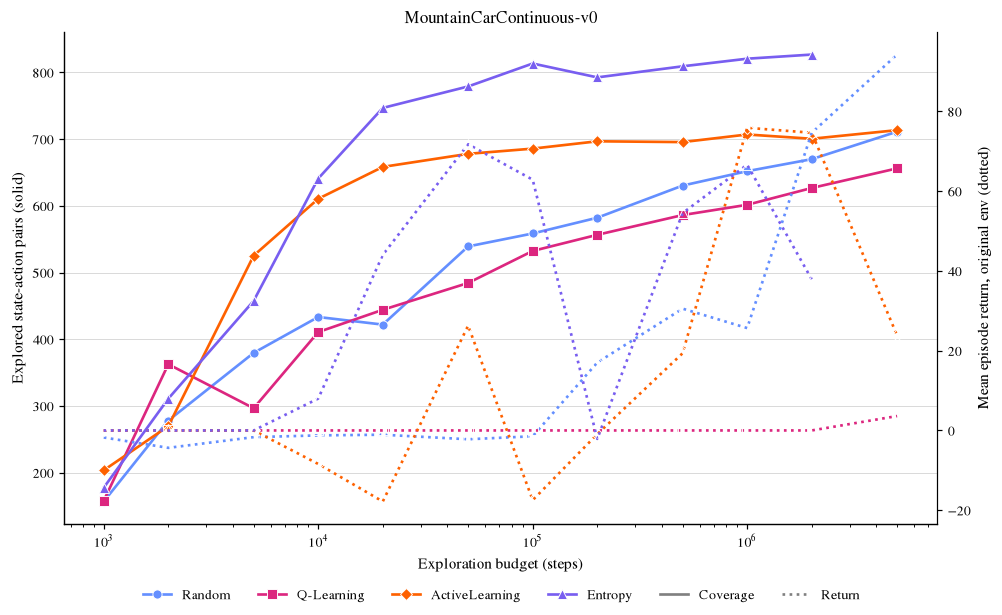

In [5]:
from matplotlib.lines import Line2D

def plot_series(ax, x, mean, lo, hi, style, **kwargs):
    ax.plot(x, mean, color=style["color"], marker=style["marker"], **kwargs)
    # if np.any(lo != hi):
    #     ax.fill_between(x, lo, hi, color=style["color"], alpha=AREA_ALPHA, linewidth=0)

fig, ax_cov = plt.subplots(figsize=(9, 5.5))
ax_val = ax_cov.twinx()

for p in policies:
    style = POLICY_STYLE[p]
    plot_series(ax_cov, *series(p, "explored_state_action_pairs"), style, label=p)
    plot_series(ax_val, *series(p, "mean_reward_original"), style, linestyle=":", markerfacecolor="none")

ax_cov.set_xscale("log")
ax_cov.set_xlabel("Exploration budget (steps)")
ax_cov.set_ylabel("Explored state-action pairs (solid)")
ax_val.set_ylabel("Mean episode return, original env (dotted)")
ax_val.spines["right"].set_visible(True)
ax_val.grid(False)
ax_cov.set_title(ENV)

# legend: color identifies the policy, line style the metric
policy_handles, policy_labels = ax_cov.get_legend_handles_labels()
metric_handles = [Line2D([], [], color=ANNOTATION_GREY, linestyle="-"),
                  Line2D([], [], color=ANNOTATION_GREY, linestyle=":")]
fig.legend(policy_handles + metric_handles, policy_labels + ["Coverage", "Return"],
           loc="outside lower center", ncol=len(policies) + 2, frameon=False)
plt.show()


### Coverage, policy value and runtime vs. budget (separate panels)

Lines show the mean over seeds. Runtime is the time to obtain the policy (exploration, model construction, stormpy
build and model checking); the evaluation of the final policy is excluded.

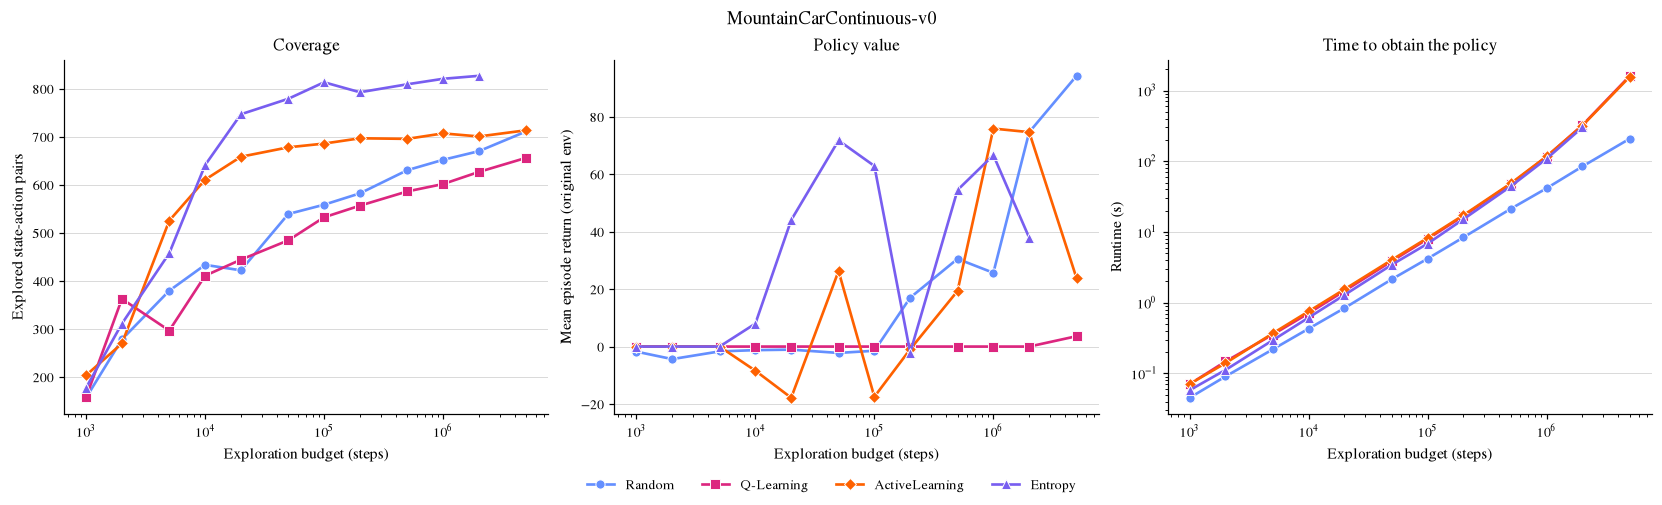

In [6]:
fig, (ax_cov, ax_val, ax_time) = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)

for p in policies:
    style = POLICY_STYLE[p]
    plot_series(ax_cov, *series(p, "explored_state_action_pairs"), style, label=p)
    plot_series(ax_val, *series(p, "mean_reward_original"), style)
    plot_series(ax_time, *series(p, "time_total"), style)

for ax in (ax_cov, ax_val, ax_time):
    ax.set_xscale("log")
    ax.set_xlabel("Exploration budget (steps)")
ax_time.set_yscale("log")

ax_cov.set_ylabel("Explored state-action pairs")
ax_cov.set_title("Coverage")
ax_val.set_ylabel("Mean episode return (original env)")
ax_val.set_title("Policy value")
ax_time.set_ylabel("Runtime (s)")
ax_time.set_title("Time to obtain the policy")

fig.suptitle(ENV)
fig.legend(*ax_cov.get_legend_handles_labels(), loc="outside lower center", ncol=len(policies), frameon=False)
plt.show()